# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import WaterBodiesDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 2841


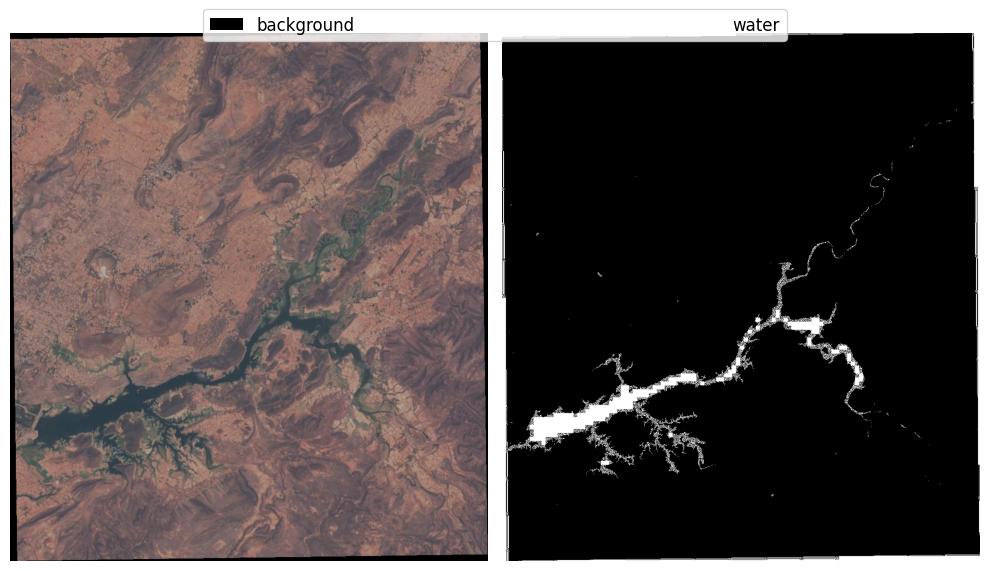

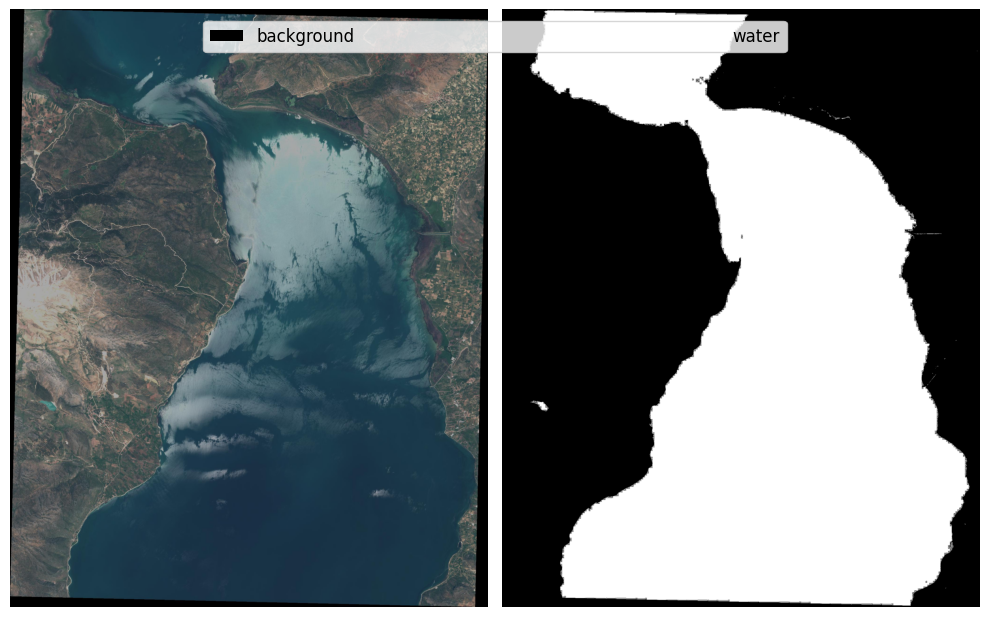

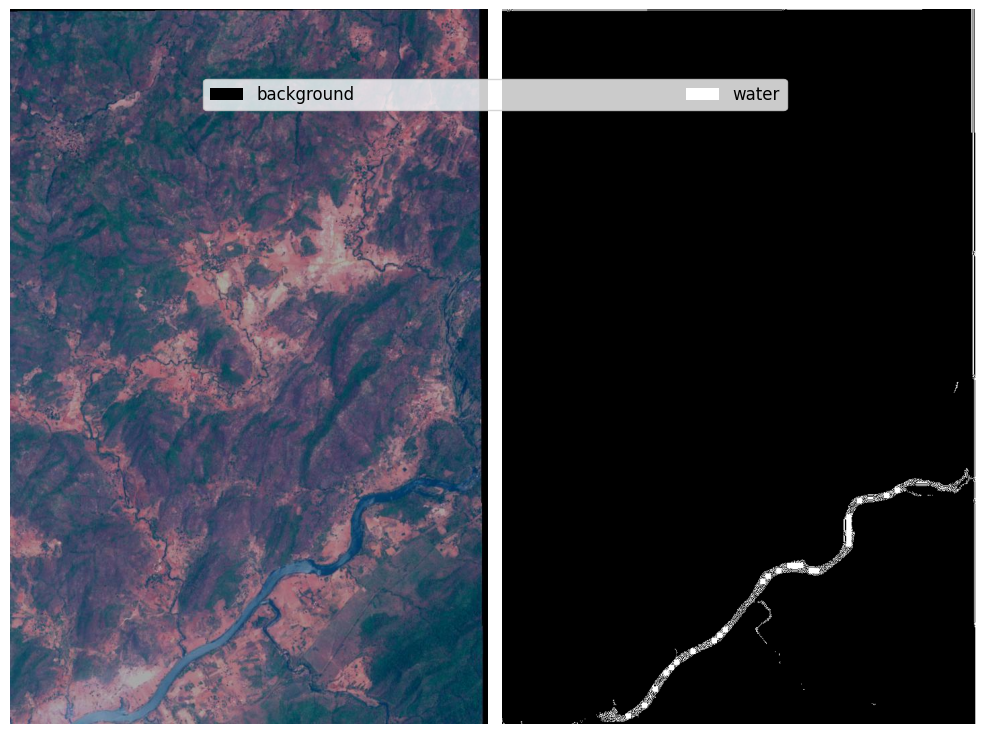

In [4]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/water_bodies"
}
dataset = WaterBodiesDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(300);
dataset.show_image(1000);

In [5]:
dataset.data_distribution_table()

,Number of pixels
background,1.039854e+09
water,5.976048e+08


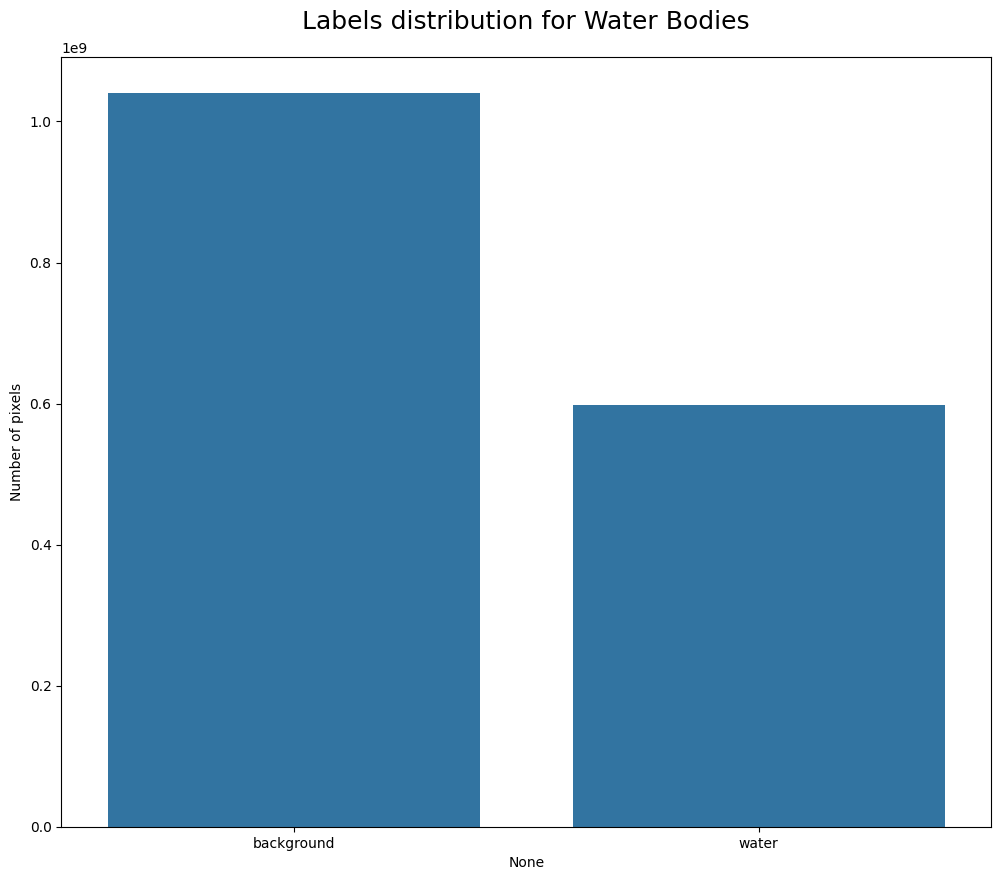

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [5]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/water_bodies",
    "csv_file": "/home/dragik/data/FAIR_EO/water_bodies/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = WaterBodiesDataset(train_dataset_config)
len(train_dataset)

2272

## Create the model

In [6]:
epochs = 5
model_directory = "/home/dragik/data/FAIR_EO/water_bodies"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-11 10:21:15,805 INFO Starting training.
training: 100%|██████████| 142/142 [38:43<00:00, 16.36s/it]
2025-03-11 10:59:59,346 INFO epoch: 1, time: 2324, loss:  0.25566
testing on train set: 100%|██████████| 142/142 [36:16<00:00, 15.33s/it] 
2025-03-11 11:36:17,309 INFO IOU:0.7737132760342823, IOU mean:0.7326701468915073, IOU per Class:[0.84770559 0.61763471]
training: 100%|██████████| 142/142 [36:17<00:00, 15.33s/it]
2025-03-11 12:12:34,467 INFO epoch: 2, time: 2177, loss:  0.16362
testing on train set: 100%|██████████| 142/142 [37:09<00:00, 15.70s/it] 
2025-03-11 12:49:44,277 INFO IOU:0.8028122347124313, IOU mean:0.7721234025168453, IOU per Class:[0.84538521 0.6988616 ]
training: 100%|██████████| 142/142 [39:14<00:00, 16.58s/it]
2025-03-11 13:28:58,468 INFO epoch: 3, time: 2354, loss:  0.13102
testing on train set: 100%|██████████| 142/142 [37:46<00:00, 15.96s/it] 
2025-03-11 14:06:45,366 INFO IOU:0.8183367636896254, IOU mean:0.7909823356699133, IOU per Class:[0.85354021 0.72842

## Evaluate the model

In [7]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/water_bodies",
    "csv_file": "/home/dragik/data/FAIR_EO/water_bodies/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = WaterBodiesDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/water_bodies/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

284


2025-03-12 09:00:08,038 INFO Loading checkpoint /home/dragik/data/FAIR_EO/water_bodies/checkpoint.pth.tar
2025-03-12 09:00:08,577 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/water_bodies/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 71/71 [06:10<00:00,  5.22s/it]


[{'IOU': 0.7858815557398623,
  'IOU mean': 0.7517544650351193,
  'IOU per Class': array([0.83412672, 0.66938221])}]

## Predictions

2025-03-12 09:07:07,372 INFO Loading checkpoint /home/dragik/data/FAIR_EO/water_bodies/checkpoint.pth.tar
2025-03-12 09:07:07,796 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/water_bodies/checkpoint.pth.tar at epoch 6


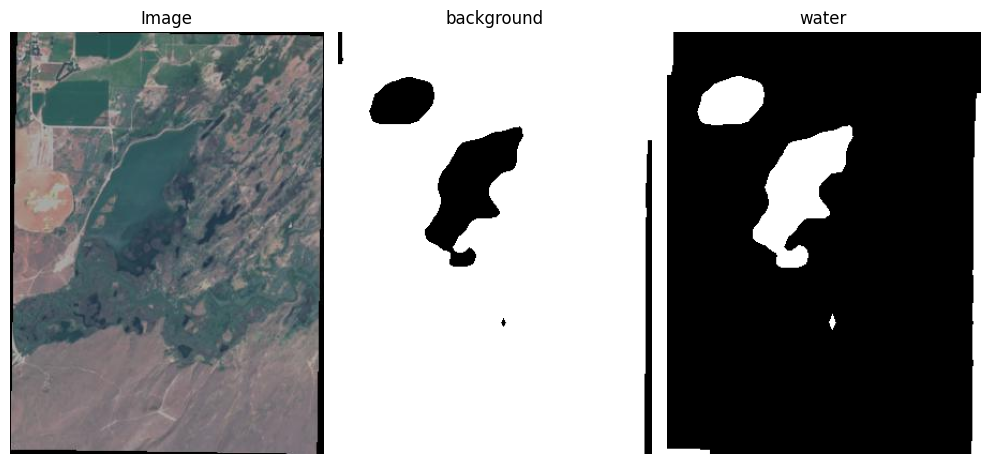

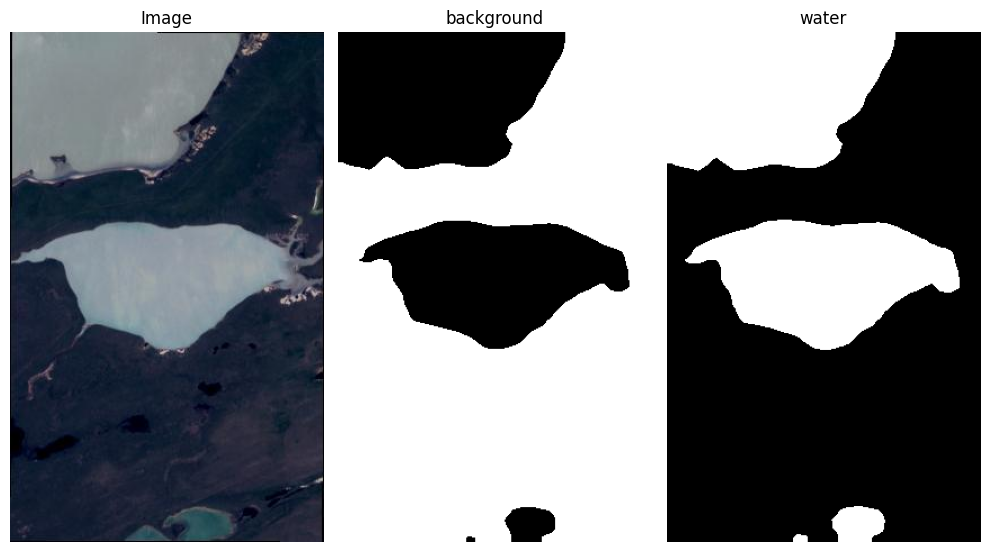

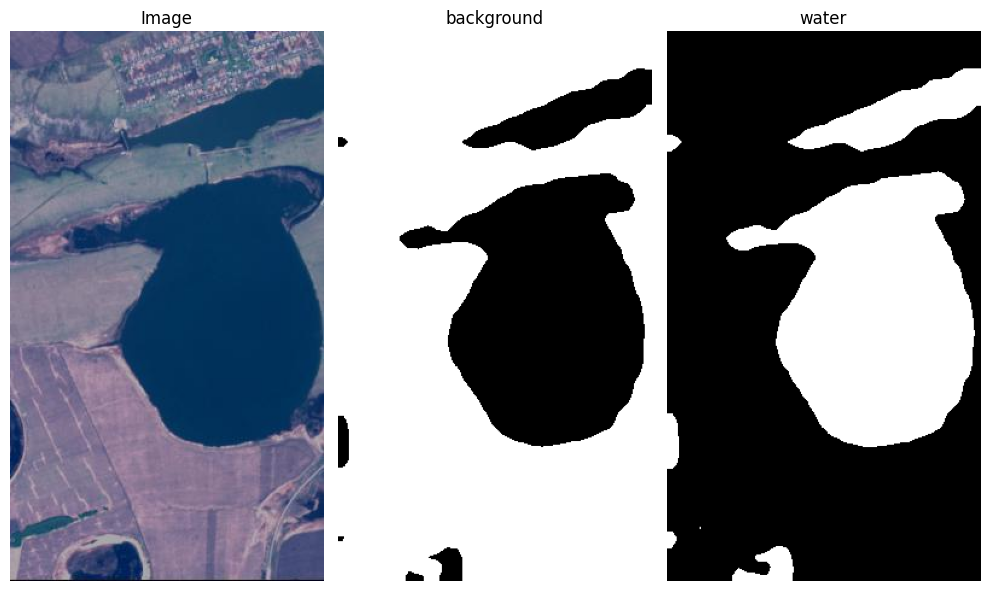

In [10]:
model_path = "/home/dragik/data/FAIR_EO/water_bodies/checkpoint.pth.tar"
labels = ["background","water"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
csv_file = "/home/dragik/data/FAIR_EO/water_bodies/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('/home/dragik/data/FAIR_EO/water_bodies/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/water_bodies/' + test_list[1])
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/water_bodies/' + test_list[10])
fig = model.predict_masks(image, labels, transform)